# 01 — Calidad e integridad de los datos

**Objetivo:** saber qué tan confiables son los datos antes de modelar.
- ¿Qué falta, qué está mal medido y qué hay que excluir?
- ¿Podemos reconstruir la secuencia del juego (turnos al bat, medias entradas)?
- ¿Cuánta muestra hay por pitcher y por pitch?
- ¿Hay diferencias de calibración de Trackman entre parques?

Toda la limpieza vive en `src/data_prep.py` para que el equipo de modelado use exactamente lo mismo.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data_prep import load_raw, build_dataset, PROCESSED_PATH, ALTITUDE_ORDER
from src.viz import set_style, savefig, ALT_COLORS, ALT_LABELS, PITCH_ORDER, CAT, MUTED
set_style(); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

raw = load_raw()
df = pd.read_parquet(PROCESSED_PATH) if PROCESSED_PATH.exists() else build_dataset(save=True)[0]
assert len(raw) == 635_002 and len(df) == len(raw)
print(f"{len(raw):,} lanzamientos | {raw.shape[1]} columnas originales | {df.shape[1]} columnas tras el pipeline")

635,002 lanzamientos | 84 columnas originales | 135 columnas tras el pipeline


## 1. Tamaño y cobertura

In [2]:
cov = pd.DataFrame({
    "pitches": raw.groupby("year").size(),
    "juegos": raw.groupby("year").game_anon_id.nunique(),
    "pitchers": raw.groupby("year").pitcher_anon_id.nunique(),
    "bateadores": raw.groupby("year").batter_anon_id.nunique(),
})
cov

,pitches,juegos,pitchers,bateadores
year,,,,
2024,243254,833,541,444
2025,256144,839,627,507
2026,135604,455,550,482


In [3]:
pd.crosstab(raw.year, raw.altitude_category.fillna("(sin dato)"), margins=True)

altitude_category,(sin dato),Extreme Altitude,Medium Altitude,No Altitude,All
year,,,,,
2024,0,66619,60934,115701,243254
2025,947,72720,65981,116496,256144
2026,2073,43928,27925,61678,135604
All,3020,183267,154840,293875,635002


## 2. Faltantes
Los datos de batazo (ExitSpeed, Angle, Distance) solo existen cuando hay contacto. Lo relevante es
**cuántos batazos en juego NO tienen medición, y si eso cambia por ambiente** (sesgo de captura de Trackman).

In [4]:
na = raw.isna().mean().sort_values(ascending=False)
na[na > 0].round(4).to_frame("share_NA")

,share_NA
Distance,0.7768
Angle,0.7121
ExitSpeed,0.7121
Direction,0.7121
hit_type,0.7102
pitcher_anon_id,0.0052
altitude_category,0.0048
catcher_anon_id,0.0037
batter_anon_id,0.0032
PitcherThrows,0.0018


In [5]:
inplay = df[df.in_play]
cap = inplay.groupby("altitude_category", observed=True).agg(
    batazos=("in_play", "size"),
    sin_exit_speed=("ExitSpeed", lambda s: s.isna().mean()),
    sin_angle=("Angle", lambda s: s.isna().mean()),
    sin_hit_type=("hit_type", lambda s: s.isna().mean()),
    sin_distance=("Distance", lambda s: s.isna().mean()),
).round(3)
cap

,batazos,sin_exit_speed,sin_angle,sin_hit_type,sin_distance
altitude_category,,,,,
No Altitude,52241,0.074,0.074,0.061,0.120
Medium Altitude,28502,0.066,0.066,0.057,0.116
Extreme Altitude,34704,0.058,0.058,0.050,0.103


## 3. Flags de calidad
No se borra nada: cada problema queda en una columna `flag_*` y `usable_stuff` los resume.

In [6]:
flags = [c for c in df.columns if c.startswith("flag_")]
desc = {
    "flag_undefined_call": "PitchCall = Undefined",
    "flag_loc_sentinel": "PlateLocHeight = 0 (valor centinela)",
    "flag_bad_extension": "Extension fuera de [3, 9] pies",
    "flag_movement_outlier": "|IVB| o |HB| > 35 pulgadas",
    "flag_release_outlier": "RelHeight fuera de [2, 8] pies",
    "flag_missing_physics": "Falta alguna variable física de Stuff+",
    "flag_no_altitude": "altitude_category vacío",
    "flag_no_pitch_type": "Pitch type Other / Knuckleball",
}
q = pd.DataFrame({"descripción": pd.Series(desc), "n": df[flags].sum(), "share": df[flags].mean().round(4)})
print(f"usable_stuff: {df.usable_stuff.mean():.2%} de los pitches")
q

usable_stuff: 97.98% de los pitches


,descripción,n,share
flag_undefined_call,PitchCall = Undefined,841,0.0013
flag_loc_sentinel,PlateLocHeight = 0 (valor centinela),6669,0.0105
flag_bad_extension,"Extension fuera de [3, 9] pies",1093,0.0017
flag_movement_outlier,|IVB| o |HB| > 35 pulgadas,9,0.0000
flag_release_outlier,"RelHeight fuera de [2, 8] pies",39,0.0001
flag_missing_physics,Falta alguna variable física de Stuff+,1555,0.0024
flag_no_altitude,altitude_category vacío,3020,0.0048
flag_no_pitch_type,Pitch type Other / Knuckleball,62,0.0001


In [7]:
pd.crosstab(raw.AutoPitchType, raw.year)

year,2024,2025,2026
AutoPitchType,,,
Changeup,30419,31228,17278
Curveball,21789,20970,11265
Cutter,9865,10815,5788
Four-Seam,84933,89113,43572
Other,26,33,2
Sinker,40705,45067,25125
Slider,52621,55657,30851
Splitter,2896,2919,1474
OneSeamFastBall,0,1,0


**Pitch types:** `Sweeper` aparece hasta 2025 (cambio de clasificación de Trackman), así que se agrupa con `Slider`
conservando `is_sweeper_label`. OneSeam/TwoSeam → Sinker; Other/Knuckleball se excluyen.
Para el modelo conviene considerar **clusters de forma de pitch** (velo + movimiento) en lugar de solo la etiqueta.

## 4. Integridad de la secuencia del juego
No hay ID de turno al bat ni número de pitch, pero las filas vienen en orden. `add_sequence_ids` reordena de forma
estable por (juego, entrada, alta/baja) — ~5% de los juegos traían entradas desordenadas — y reconstruye los PAs.

In [8]:
pa = df.groupby("pa_id").agg(terminal=("pa_terminal", "last"), n=("pa_id", "size"))
hi_last = df.groupby("half_inning_id").tail(1)
outs_end = (hi_last.Outs + hi_last.OutsOnPlay).astype(float)
nxt_same = df.pa_id.eq(df.pa_id.shift(-1))
b_ok = (df.Balls.shift(-1) - df.Balls).where(nxt_same).dropna().isin([0, 1]).mean()
s_ok = (df.Strikes.shift(-1) - df.Strikes).where(nxt_same).dropna().isin([0, 1]).mean()
seq = pd.Series({
    "turnos al bat reconstruidos": len(pa),
    "% PAs que terminan en evento terminal": pa.terminal.mean(),
    "pitches por PA (media)": pa.n.mean(),
    "% medias entradas que terminan con 3 outs": (outs_end >= 3).mean(),
    "% medias entradas que terminan con 2 outs (out en las bases / walk-off)": (outs_end == 2).mean(),
    "% transiciones de bolas válidas dentro del PA": b_ok,
    "% transiciones de strikes válidas dentro del PA": s_ok,
})
assert pa.terminal.mean() > 0.95
seq.round(4).to_frame("valor")

,valor
turnos al bat reconstruidos,166353.0000
% PAs que terminan en evento terminal,0.9899
pitches por PA (media),3.8172
% medias entradas que terminan con 3 outs,0.9165
% medias entradas que terminan con 2 outs (out en las bases / walk-off),0.0779
% transiciones de bolas válidas dentro del PA,0.9990
% transiciones de strikes válidas dentro del PA,0.9994


## 5. Muestra por pitcher
Referencia FanGraphs: Stuff+ se estabiliza con ~80 pitches; Location+ con ~400.

pitchers                                    1039
pitchers con >= 400 pitches                  513
pitcher-pitch types con >= 80 pitches       2005
pitcher-pitch types con < 80 pitches        3838
pitchers que lanzaron en las 3 altitudes     665
pitchers que lanzaron en 2 altitudes         200


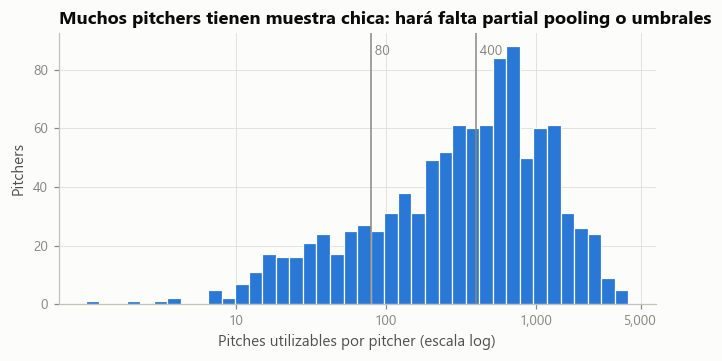

In [9]:
n_p = df[df.usable_stuff].groupby("pitcher_anon_id").size()
n_pt = df[df.usable_stuff].groupby(["pitcher_anon_id", "pitch_type"]).size()
envs = df.groupby("pitcher_anon_id").altitude_category.nunique()
print(pd.Series({
    "pitchers": len(n_p),
    "pitchers con >= 400 pitches": (n_p >= 400).sum(),
    "pitcher-pitch types con >= 80 pitches": (n_pt >= 80).sum(),
    "pitcher-pitch types con < 80 pitches": (n_pt < 80).sum(),
    "pitchers que lanzaron en las 3 altitudes": (envs == 3).sum(),
    "pitchers que lanzaron en 2 altitudes": (envs == 2).sum(),
}).to_string())

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(np.log10(n_p), bins=40, color=CAT[0], edgecolor="#fcfcfb", linewidth=0.8)
for v, lab in [(80, "80"), (400, "400")]:
    ax.axvline(np.log10(v), color=MUTED, lw=1)
    ax.text(np.log10(v), ax.get_ylim()[1] * 0.92, f" {lab}", color=MUTED, fontsize=9)
ax.set_xticks(np.log10([10, 100, 1000, 5000])); ax.set_xticklabels(["10", "100", "1,000", "5,000"])
ax.set_xlabel("Pitches utilizables por pitcher (escala log)"); ax.set_ylabel("Pitchers")
ax.set_title("Muchos pitchers tienen muestra chica: hará falta partial pooling o umbrales")
savefig(fig, "01_muestra_por_pitcher"); plt.show()

## 6. ¿Hay sesgo de calibración de Trackman por parque?
Comparamos **al mismo pitcher con el mismo pitch y la misma temporada** en distintos ambientes (centrando cada variable
en la media del pitcher-pitch-temporada). Las variables del release (altura, extensión) **no deberían** cambiar por la
física del aire; si cambian, es calibración. La pérdida de velocidad y el movimiento **sí** deberían cambiar.

In [10]:
cols = {"RelSpeed": "Velocidad (mph)", "RelHeight": "Altura release (pies)", "Extension": "Extensión (pies)",
        "SpinRate": "Spin (rpm)", "speed_drop_pct": "% vel. perdida", "InducedVertBreak": "IVB (pulg.)", "hb_arm": "HB lado brazo (pulg.)"}
u = df[df.usable_stuff & df.altitude_category.notna()].copy()
key = ["pitcher_anon_id", "pitch_type", "year"]
multi = u.groupby(key).altitude_category.transform("nunique") >= 2
u = u[multi]
for c in cols:
    u[c + "_c"] = u[c] - u.groupby(key)[c].transform("mean")
within = u.groupby("altitude_category", observed=True)[[c + "_c" for c in cols]].mean()
within.columns = list(cols.values())
within["% vel. perdida"] *= 100
within.round(3)

,Velocidad (mph),Altura release (pies),Extensión (pies),Spin (rpm),% vel. perdida,IVB (pulg.),HB lado brazo (pulg.)
altitude_category,,,,,,,
No Altitude,-0.053,0.002,-0.025,-5.944,0.426,0.741,0.598
Medium Altitude,0.052,-0.014,0.018,9.261,-0.206,-0.464,-0.330
Extreme Altitude,0.040,0.008,0.025,1.498,-0.502,-0.781,-0.670


**Lectura:** si la altura del release o la extensión cambian sistemáticamente con la altitud dentro del mismo pitcher,
es señal de calibración por parque y conviene **normalizar esas variables por parque** antes de modelar.
La velocidad de salida también puede variar por calibración del radar.

In [11]:
by_park = u.groupby("park_id")[["RelHeight_c", "Extension_c", "RelSpeed_c", "SpinRate_c"]].agg(["mean", "size"])
by_park = by_park.xs("mean", axis=1, level=1).join(by_park[("RelHeight_c", "size")].rename("n"))
by_park = by_park[by_park.n >= 2000].sort_values("Extension_c")
print("Desviación media por parque (mismo pitcher-pitch-temporada) — rango entre parques:")
print((by_park.drop(columns="n").max() - by_park.drop(columns="n").min()).round(3).to_string())
by_park.round(3)

Desviación media por parque (mismo pitcher-pitch-temporada) — rango entre parques:
RelHeight_c      0.181
Extension_c      0.380
RelSpeed_c       0.504
SpinRate_c     179.764


,RelHeight_c,Extension_c,RelSpeed_c,SpinRate_c,n
park_id,,,,,
PK01,-0.031,-0.226,-0.358,15.683,10454
PK22,-0.103,-0.167,0.145,32.018,15116
PK13,0.054,-0.133,-0.031,14.462,37496
PK21,-0.008,-0.130,-0.077,2.245,18593
PK08,0.003,-0.098,0.050,-27.211,35938
PK14,-0.046,-0.070,0.137,-147.746,28914
PK12,0.051,-0.050,-0.055,18.301,44106
PK09,0.048,-0.039,-0.173,-7.190,36656
PK02,0.024,0.002,0.027,13.540,40350


## Resumen para el equipo
- Datos limpios y consistentes en ~98% de los pitches; los problemas quedan marcados con `flag_*`.
- La secuencia se reconstruye bien (>98% de PAs cierran en evento terminal) → podemos tener `prev_pitch_type`,
  número de pitch y veces en el orden.
- Hay muchos pitchers con poca muestra: el modelo debe regularizar (umbrales mínimos o modelos jerárquicos).
- Revisar la tabla de calibración por parque: lo que cambie en release/extensión no es física.